## STAT 2850A - Introduction to Data Science ##

## Fall 2026 ##
## Project part 2 ## 

The second part of the project is concerned with analysing and cleaning the dataset. You are assigned a different dataset (see table below) than the one from the first phase of the project. The context of the dataset and a short description was done by one of your colleagues and the file is provided in the same folder as the dataset. In the short report some of the limitations of the dataset were highlighted as well as potential research questions.


For the second part of the project, focus on one of the research questions proposed in the short report made during phase 1. Given the selected question, you will need to prepare and submit the following documents/files:
* **A file csv or excel** containing the clean dataset. In the process of cleaning, you may consider the following:
    * missing values, duplicates, incorrect data types, inconsistent formatting.
    * redundant variables for the research question.
    * structural errors, e.g., typos, mismatched naming conventions.
    * outliers and anomalies.
      
  *Note:* some of the issues were already discussed in phase 1. If this is the case, you may consider fixing those issues, whenever possible. *(30 points)*
* **A Jupyter Notebook file ipynb** with the code to clean the data. You need to add comments to each line of code and short justifications, whenever possible. *(35 points)*
* **The exported PDF of the Jupyter Notebook.**
* **A document PDF/docx** to explain the issues that you found and one approach to solve them. At the end of the file, provide comments about the potential difficulties that you have encountered in your analysis. *(35 points)*


*Note:*
* Your clean dataset will be used by other colleagues in the third part of the project. Thus, it is important to help them to understand the choices you made while analyzing and cleaning the data.
* Please refer to the *general information* for the use of AI.  

In [53]:
# Reading and loading the Data into the notebook

library(dplyr) # Install dplyr package for variable manipulation
library(readxl) # Install readxl package to read xlsx file
install.packages("writexl")
data <- read_excel("Dataset5.xlsx") # Load the excel into a dataframe

Installing package into ‘/home/jupyter/R/x86_64-pc-linux-gnu-library/4.5’
(as ‘lib’ is unspecified)

Warning message:
“Expecting numeric in N1142 / R1142C14: got '.'”
Warning message:
“Expecting numeric in AC1185 / R1185C29: got '.'”
Warning message:
“Expecting numeric in AC1200 / R1200C29: got '.'”


In [54]:
# Overview of the data

head(data) # General View of the raw data
dim(data) # Dimenstion of the raw data
summary(data) # 

"The contents of this survey are intended solely for academic purposes. During the process of collecting, processing and analyzing the information you provide, it won´t be possible to identify any respondent. Are you willing to participate in this survey?",1. Gender,2. Year of birth,3. Which is the socio-economic strata of your household?,"4. According to your cultural, ethnic group or physical characteristics, how do you recognize yourself?",5.1 What is the highest education level you reached (even if you didn't finish) and the last grade approved in this level? Level,5.2 What is the highest education level you reached (even if you didn't finish) and the last grade approved in this level? Year,6.1 How many years of education your parents attained? Father,6.2 How many years of education your parents attained? Mother,"7. In general, how satisfied are you with your life?",⋯,"21. If a large group of citizens expresses dissatisfaction with the functioning of a public service (e.g. the education, health or justice system), do you think that corrective actions will be taken?","22. If a natural disaster occurs, do you think that the provision by government of adequate food, shelter and clothing will be available to people who are affected?","23. If money is offered by citizens to government employees in order to speed up administrative procedures, do you think that they will refuse the bribe?","24. If a parliamentarian could influence the award of a government contract and receive a bribe in return, do you think that he/she will reject the bribe?","25. If a high level politician would be offered a well-paid job in the private sector in exchange for political influence, do you think that he/she will reject the job?","26. If you need information about an administrative procedure, do you think that it will be easy to find?","27. If a decision affecting your community is to be taken by the local or regional government, how likely is it that you will be consulted?","28. If you participate in a public consultation, do you think that your opinion will be considered?","29. If a citizen belongs to a social minority (e.g. sexual, racial/ethnic and/or based on nationality), how likely is it that he or she will be treated equally by a government agency?","30. If a tax reform is implemented, do you think that the financial burden would be shared fairly across social groups?"
<dbl>,<dbl>,<chr>,<dbl>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<chr>,⋯,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<dbl>
1,2,1959,2,1,1,3,0,2,8,⋯,8,3,8,9,6,3,4,4,5,3
1,1,1986,1,2,4,11,16,5,8,⋯,9,7,3,5,5,3,2,3,4,2
1,1,1965,5,4,4,11,99,99,5,⋯,1,3,5,5,5,4,3,2,4,3
1,2,1985,4,2,7,18,11,13,6,⋯,1,1,10,10,1,1,0,2,5,1
1,3,1993,3,2,3,7,99,99,10,⋯,8,8,8,6,6,6,6,88,4,4
1,2,1981,2,2,4,11,2,2,7,⋯,6,4,4,5,7,6,2,1,9,3


[1] 1237   34

 The contents of this survey are intended solely for academic purposes. During the process of collecting, processing and analyzing the information you provide, it won´t be possible to identify any respondent. Are you willing to participate in this survey?
 Min.   :1                                                                                                                                                                                                                                                     
 1st Qu.:1                                                                                                                                                                                                                                                     
 Median :1                                                                                                                                                                                                                              

In [55]:
# Variable Renaming

data = data %>% # Variable Renamed to appropriate names
    rename(
        permission = `The contents of this survey are intended solely for academic purposes. During the process of collecting, processing and analyzing the information you provide, it won´t be possible to identify any respondent. Are you willing to participate in this survey?`,
        gender = `1. Gender`,
        birth_year = `2. Year of birth`,
        economic_strata = `3. Which is the socio-economic strata of your household?`,
        ethnicity = `4. According to your cultural, ethnic group or physical characteristics, how do you recognize yourself?`,
        edu_level = `5.1 What is the highest education level you reached (even if you didn\'t finish) and the last grade approved in this level? Level`,
        edu_year = `5.2 What is the highest education level you reached (even if you didn\'t finish) and the last grade approved in this level? Year`,
        edu_father = `6.1 How many years of education  your parents attained? Father`,
        edu_mother = `6.2 How many years of education  your parents attained? Mother`,
        life_satisfaction = `7. In general, how satisfied are you with your life?`,
        happy = `8. How about happy?`,
        worried = `9. How about worried?`,
        depressed = `10. How about depressed?`,
        general_health = `11. Would you say that in general your health is`,
        physical_not_good = `12. Now thinking about your physical health, which includes physical illness and injury, for how many days during the past 30 days was your physical health not good?`,
        mental_not_good = `13. Now thinking about your mental health, which includes stress, depression, and problems with emotions, for how many days during the past 30 days was your mental health not good?`,
        trust_people = `14. In general, how much do you trust most people?`,
        trust_know_people = `15. In general, how much do you trust most people you know personally?`,
        return_neighbour = `16. Do you think your wallet (or your valuables) would be returned to you if it were found by a neighbour?`,
        return_stranger = `17. Do you think your wallet (or your valuables) would be returned to you if it were found by a stranger?`,
        city_council = `17. City Council?`,
        police = `18. The Police?`,
        civil_service = `19. The civil service?`,
        complain_pubserv_resolved = `20. If you complain about bad quality of a public service, how likely is that the problem will be easily resolved?`,
        group_pubserv_action = `21. If a large group of citizens expresses dissatisfaction with the functioning of a public service (e.g. the education, health or justice system), do you think that corrective actions will be taken?`,
        natdis_gov = `22. If a natural disaster occurs, do you think that the provision by government of adequate food, shelter and clothing will be available to people who are affected?`,
        money_bribe = `23. If money is offered by citizens to government employees in order to speed up administrative procedures, do you think that they will refuse the bribe?`,
        parliament_bribe = `24. If a parliamentarian could influence the award of a government contract and receive a bribe in return, do you think that he/she will reject the bribe?`,
        politician_influence = `25. If a high level politician would be offered a well-paid job in the private sector in exchange for political influence, do you think that he/she will reject the job?`,
        admin_info = `26. If you need information about an administrative procedure, do you think that it will be easy to find?`,
        consult_decision = `27.  If a decision affecting your community is to be taken by the local or regional government, how likely is it that you will be consulted?`,
        opinion_consider = `28. If you participate in a public consultation, do you think that your opinion will be considered?`,
        minority_treated = `29. If a citizen belongs to a social minority (e.g. sexual, racial/ethnic and/or based on nationality), how likely is it that he or she will be treated equally by a government agency?`,
        tax_reform = `30. If a tax reform is implemented, do you think that the financial burden would be shared fairly across social groups?`
    )

In [56]:
# Variable Type

str(data) # Check initial variable types

# Converted to Factor:
data$permission = as.factor(data$permission)
data$gender = as.factor(data$gender)
data$economic_strata = as.factor(data$economic_strata)
data$ethnicity = as.factor(data$ethnicity)
data$edu_level = as.factor(data$edu_level)
data$general_health = as.factor(data$general_health)
data$return_neighbour = as.factor(data$return_neighbour)
data$return_stranger = as.factor(data$return_stranger)

# Converted to Numeric:
data$birth_year = as.numeric(data$birth_year)
data$edu_year = as.numeric(data$edu_year)
data$life_satisfaction = as.numeric(data$life_satisfaction)
data$money_bribe = as.numeric(data$money_bribe)
data$admin_info = as.numeric(data$admin_info)
data$consult_decision = as.numeric(data$consult_decision)
data$opinion_consider = as.numeric(data$opinion_consider)
data$minority_treated = as.numeric(data$minority_treated)

print("-------------------------------------NEW VARIABLE TYPE---------------------------------------")

str(data) # check if the changes were applied correctly

tibble [1,237 × 34] (S3: tbl_df/tbl/data.frame)
 $ permission               : num [1:1237] 1 1 1 1 1 1 1 1 1 1 ...
 $ gender                   : num [1:1237] 2 1 1 2 3 2 2 2 2 2 ...
 $ birth_year               : chr [1:1237] "1959" "1986" "1965" "1985" ...
 $ economic_strata          : num [1:1237] 2 1 5 4 3 2 4 1 2 1 ...
 $ ethnicity                : chr [1:1237] "1" "2" "4" "2" ...
 $ edu_level                : num [1:1237] 1 4 4 7 3 4 1 3 3 5 ...
 $ edu_year                 : chr [1:1237] "3" "11" "11" "18" ...
 $ edu_father               : num [1:1237] 0 16 99 11 99 2 8 11 99 11 ...
 $ edu_mother               : num [1:1237] 2 5 99 13 99 2 0 5 4 0 ...
 $ life_satisfaction        : chr [1:1237] "8" "8" "5" "6" ...
 $ happy                    : num [1:1237] 6 9 9 1 7 6 9 10 10 0 ...
 $ worried                  : num [1:1237] 5 2 5 2 0 4 0 0 3 5 ...
 $ depressed                : num [1:1237] 5 0 2 8 0 1 0 0 0 5 ...
 $ general_health           : num [1:1237] 4 3 3 3 1 3 4 3 3 1 ...
 $ 

Warning message:
“NAs introduced by coercion”
Warning message:
“NAs introduced by coercion”
Warning message:
“NAs introduced by coercion”
Warning message:
“NAs introduced by coercion”
Warning message:
“NAs introduced by coercion”
Warning message:
“NAs introduced by coercion”
Warning message:
“NAs introduced by coercion”


[1] "-------------------------------------NEW VARIABLE TYPE---------------------------------------"
tibble [1,237 × 34] (S3: tbl_df/tbl/data.frame)
 $ permission               : Factor w/ 1 level "1": 1 1 1 1 1 1 1 1 1 1 ...
 $ gender                   : Factor w/ 3 levels "1","2","3": 2 1 1 2 3 2 2 2 2 2 ...
 $ birth_year               : num [1:1237] 1959 1986 1965 1985 1993 ...
 $ economic_strata          : Factor w/ 6 levels "1","2","3","4",..: 2 1 5 4 3 2 4 1 2 1 ...
 $ ethnicity                : Factor w/ 7 levels ".","1","2","3",..: 2 3 5 3 3 3 3 5 3 3 ...
 $ edu_level                : Factor w/ 9 levels "1","2","3","4",..: 1 4 4 7 3 4 1 3 3 5 ...
 $ edu_year                 : num [1:1237] 3 11 11 18 7 11 2 7 8 14 ...
 $ edu_father               : num [1:1237] 0 16 99 11 99 2 8 11 99 11 ...
 $ edu_mother               : num [1:1237] 2 5 99 13 99 2 0 5 4 0 ...
 $ life_satisfaction        : num [1:1237] 8 8 5 6 10 7 10 10 8 8 ...
 $ happy                    : num [1:1237] 6 9 9 1 7

In [57]:
# Assign survey ID number for uniqueness

data = data %>% # Take data and pass it to mutate function 
    mutate(survey_id = row_number()) %>% # Create a new column and create ID and then pass it to relocate
    relocate(survey_id) # Relocate the ID column from last to first by default

head(data) # Check if the survey ID is in the correct position
raw_total = length(data$survey_id) # Total number of survey data from raw data
raw_total

survey_id,permission,gender,birth_year,economic_strata,ethnicity,edu_level,edu_year,edu_father,edu_mother,⋯,group_pubserv_action,natdis_gov,money_bribe,parliament_bribe,politician_influence,admin_info,consult_decision,opinion_consider,minority_treated,tax_reform
<int>,<fct>,<fct>,<dbl>,<fct>,<fct>,<fct>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,1,2,1959,2,1,1,3,0,2,⋯,8,3,8,9,6,3,4,4,5,3
2,1,1,1986,1,2,4,11,16,5,⋯,9,7,3,5,5,3,2,3,4,2
3,1,1,1965,5,4,4,11,99,99,⋯,1,3,5,5,5,4,3,2,4,3
4,1,2,1985,4,2,7,18,11,13,⋯,1,1,10,10,1,1,0,2,5,1
5,1,3,1993,3,2,3,7,99,99,⋯,8,8,8,6,6,6,6,88,4,4
6,1,2,1981,2,2,4,11,2,2,⋯,6,4,4,5,7,6,2,1,9,3


[1] 1237

In [58]:
# Duplicated data:

data %>% # Take the data and select it without Survey ID
    select(-survey_id) %>% # Removing survey ID from selection
    duplicated() %>% # Check if the selected variables are duplicated
    sum() # Sum all the duplicated columns

count_na = colSums(is.na(data)) # count of all the NA in all columns
count_na[count_na > 0] # Only the columns with more than 0 NA

count_dot = sapply(data, function(x) { # apply the condition where x as a character is equals to ".", excluding NA
    sum(as.character(x) == ".", na.rm = TRUE) # Count all the observation where the condition is met
    })
count_dot[count_dot > 0] # Only the columns with more than 0 "." character

colSums(is.na(data) & sapply(data, function(x) { # Apply the condition where x as a character is equals to ".", excluding NA
    sum(as.character(x) == ".", na.rm = TRUE) # Count all the observation where the condition is met
    }))

[1] 0

birth_year    life_satisfaction       general_health 
                   2                    1                    1 
         money_bribe politician_influence           admin_info 
                   1                    2                    1 
    consult_decision     opinion_consider     minority_treated 
                   2                    4                    1

ethnicity return_neighbour  return_stranger 
               2                8                7

survey_id                permission                    gender 
                        0                         0                         0 
               birth_year           economic_strata                 ethnicity 
                        0                         0                         0 
                edu_level                  edu_year                edu_father 
                        0                         0                         0 
               edu_mother         life_satisfaction                     happy 
                        0                         0                         0 
                  worried                 depressed            general_health 
                        0                         0                         0 
        physical_not_good           mental_not_good              trust_people 
                        0                         0                         0 
        trust_know_people          return_neighbour           return_stranger 
                        0                         0                         0 
             city_council                    police             civil_service 
                        0                         0                         0 
complain_pubserv_resolved      group_pubserv_action                natdis_gov 
                        0                         0                         0 
              money_bribe          parliament_bribe      politician_influence 
                        0                         0                         0 
               admin_info          consult_decision          opinion_consider 
                        0                         0                         0 
         minority_treated                tax_reform 
                        0                         0

In [59]:
# Handling missing data (NA and ".") Justification
total_missing = 1 + 1 + 1 + 2 + 1 + 2 + 4 + 1 + 2 + 2 + 8 + 7 + 2 # All of the missing data (both NA and ".")

percent_missing = total_missing/raw_total * 100 # Calculate the percentage of data that are missing
percent_missing # Print percent

[1] 2.748585

In [60]:
# With 2.74858528698464% of data being reported as NA or ".", we can remove it since it is not a big chunk of data

clean_data = data %>% # Take the clean data and filter it to remove NA
    filter(complete.cases(data)) %>%  # Pass the result to another filter that looks at all data and removes "."
    filter(!if_any(everything(), ~ as.character(.) == "."))

colSums(is.na(clean_data)) # Sum all the columns with NA (check to see if there are any NA's left)

sapply(clean_data, function(x) { #Take the clean data and sum all the x that equates to "."
    sum(as.character(x) == ".", na.rm = TRUE) # Exclude NA's in the comparison and print it out (check to see if there are any "." left)
    })

survey_id                permission                    gender 
                        0                         0                         0 
               birth_year           economic_strata                 ethnicity 
                        0                         0                         0 
                edu_level                  edu_year                edu_father 
                        0                         0                         0 
               edu_mother         life_satisfaction                     happy 
                        0                         0                         0 
                  worried                 depressed            general_health 
                        0                         0                         0 
        physical_not_good           mental_not_good              trust_people 
                        0                         0                         0 
        trust_know_people          return_neighbour           return_stranger 
                        0                         0                         0 
             city_council                    police             civil_service 
                        0                         0                         0 
complain_pubserv_resolved      group_pubserv_action                natdis_gov 
                        0                         0                         0 
              money_bribe          parliament_bribe      politician_influence 
                        0                         0                         0 
               admin_info          consult_decision          opinion_consider 
                        0                         0                         0 
         minority_treated                tax_reform 
                        0                         0

survey_id                permission                    gender 
                        0                         0                         0 
               birth_year           economic_strata                 ethnicity 
                        0                         0                         0 
                edu_level                  edu_year                edu_father 
                        0                         0                         0 
               edu_mother         life_satisfaction                     happy 
                        0                         0                         0 
                  worried                 depressed            general_health 
                        0                         0                         0 
        physical_not_good           mental_not_good              trust_people 
                        0                         0                         0 
        trust_know_people          return_neighbour           return_stranger 
                        0                         0                         0 
             city_council                    police             civil_service 
                        0                         0                         0 
complain_pubserv_resolved      group_pubserv_action                natdis_gov 
                        0                         0                         0 
              money_bribe          parliament_bribe      politician_influence 
                        0                         0                         0 
               admin_info          consult_decision          opinion_consider 
                        0                         0                         0 
         minority_treated                tax_reform 
                        0                         0

In [61]:
# Handling unknown or DK observations by replacing it with NA

# Group all the variables with 99 as a code for unknown
dk_99 = c("edu_father",
          "edu_mother",
          "general_health",
          "physical_not_good",
          "mental_not_good")

# Group all the varaibles with 88 as a code for unknown
dk_88 = c("trust_people", 
          "trust_know_people",
          "city_council",
          "police",
          "civil_service",
          "complain_pubserv_resolved",
          "group_pubserv_action",
          "natdis_gov",
          "money_bribe",
          "parliament_bribe",
          "politician_influence",
          "admin_info",
          "consult_decision",
          "opinion_consider",
          "minority_treated",
          "tax_reform")

# Change all the unknown or DK to NA's 
clean_data = clean_data %>% # Take the clean data and allow mutation
    mutate( # Mutate it 
        across( # Take the variable
            all_of(dk_99), # Takes all observation that is 99
            ~ replace(.x, .x == 99, NA) # Raplace it with NA instead
            )
        )

clean_data = clean_data %>% # Take the clean data to allow mutation
    mutate( # Mutate it
        across( # Take the variable
            all_of(dk_88), # Takes all observation that is 88
            ~ replace(.x, .x == 88, NA) # Replace all 88 with NA 
            )
        )

# Check if there isn't any unchanged variable left
sapply(clean_data[dk_99], function(x) { # Make a function x such that it sums all the 99 in the column
  sum(x == 99, na.rm = TRUE) # Sums the 99 but excludes NA
})

sapply(clean_data[dk_88], function(x) { # Make a function x such that it sums all the 88 in the column
  sum(x == 88, na.rm = TRUE) # Sums the 88 but excludes NA
})

edu_father        edu_mother    general_health physical_not_good 
                0                 0                 0                 0 
  mental_not_good 
                0

trust_people         trust_know_people              city_council 
                        0                         0                         0 
                   police             civil_service complain_pubserv_resolved 
                        0                         0                         0 
     group_pubserv_action                natdis_gov               money_bribe 
                        0                         0                         0 
         parliament_bribe      politician_influence                admin_info 
                        0                         0                         0 
         consult_decision          opinion_consider          minority_treated 
                        0                         0                         0 
               tax_reform 
                        0

In [62]:
# Handling invalid observtions in ranged variables

# Group all the variables with the range 1 - 10
variable_range = c("trust_people", 
                   "trust_know_people",
                   "city_council",
                   "police",
                   "civil_service",
                   "complain_pubserv_resolved",
                   "group_pubserv_action",
                   "natdis_gov",
                   "money_bribe",
                   "parliament_bribe",
                   "politician_influence",
                   "admin_info",
                   "consult_decision",
                   "opinion_consider",
                   "minority_treated",
                   "tax_reform")

# Check all the observations that is out of range
sapply(clean_data[variable_range], function(x) { # Makes a function x that sums all the numbers that are not NA and are out of range
  sum(!is.na(x) & (x < 1 | x > 10))
})

# Replace all the out of range values with NA
clean_data = clean_data %>% # Take the data
    mutate( # Allow mutation
        across(  # Apply multiple functions to all variables
            all_of(variable_range), # Take this set of variables
            ~ replace(.x, !is.na(.x) & (.x < 1 | .x > 10), NA) # Replace all the .x that is not NA and out of range with NA
            )
        )

# Check if there are still variables that are out of range
sapply(clean_data[variable_range], function(x) { # Makes a function x that sums all the numbers that are not NA and are out of range
  sum(!is.na(x) & (x < 1 | x > 10))
})

trust_people         trust_know_people              city_council 
                      175                        66                       342 
                   police             civil_service complain_pubserv_resolved 
                      262                       423                       275 
     group_pubserv_action                natdis_gov               money_bribe 
                      106                        84                        19 
         parliament_bribe      politician_influence                admin_info 
                       16                        46                        79 
         consult_decision          opinion_consider          minority_treated 
                      248                       212                       182 
               tax_reform 
                      301

trust_people         trust_know_people              city_council 
                        0                         0                         0 
                   police             civil_service complain_pubserv_resolved 
                        0                         0                         0 
     group_pubserv_action                natdis_gov               money_bribe 
                        0                         0                         0 
         parliament_bribe      politician_influence                admin_info 
                        0                         0                         0 
         consult_decision          opinion_consider          minority_treated 
                        0                         0                         0 
               tax_reform 
                        0

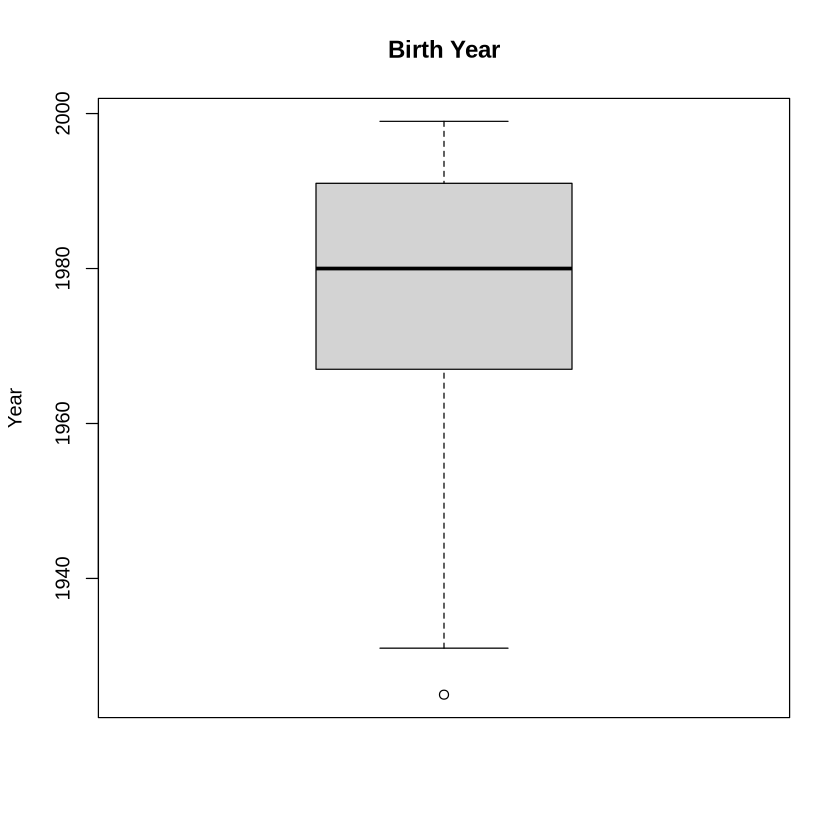

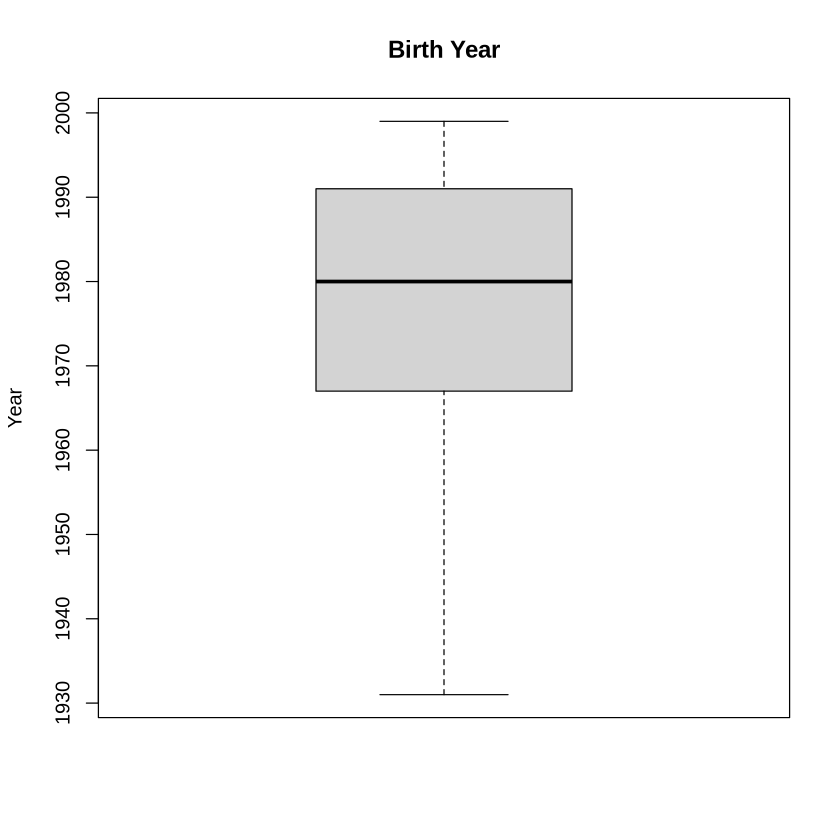

In [63]:
# Outlier for Birth Year:

# Boxplot for inital data
boxplot(clean_data$birth_year,
       main = "Birth Year",
       ylab = "Year")

# Make ourlier NA 
clean_data$birth_year[clean_data$birth_year == 1925] = NA # Took from the minimum number as it is an outlier

# Check for other outliers
boxplot(clean_data$birth_year,
       main = "Birth Year",
       ylab = "Year")

In [64]:
# Final Cleaning

# Group the variables that are redundant based on the research question
drop_variables = c("permission",
                   "complain_pubserv_resolved",
                   "group_pubserv_action",
                   "money_bribe",
                   "parliament_bribe",
                   "politician_influence",
                   "admin_info")

# Dropp all the variables
clean_data = clean_data %>%
    select(-all_of(drop_variables))

# Check which columns have NA (as DK) to determine missing data in variable
na_columns = colSums(is.na(clean_data))
na_columns[na_columns > 0]

birth_year        edu_father        edu_mother   mental_not_good 
                1               342               263                 1 
     trust_people trust_know_people      city_council            police 
              175                67               520               273 
    civil_service        natdis_gov  consult_decision  opinion_consider 
              479                96               290               262 
 minority_treated        tax_reform 
              210               343

In [65]:
# Justification for the unuased data
clean_total = length(clean_data$survey_id) # total survey after data cleaning

cc_na_percent = 520/clean_total * 100 # Percent of missing data in City Council
cs_na_percent = 479/clean_total * 100 # Percent of missing data in Civil Service
tr_na_percent = 343/clean_total * 100 # Percent of missin data in tax reform

cc_na_percent
cs_na_percent
tr_na_percent

# Remove city council as it has too much missing data
clean_data = clean_data %>% 
    select(-city_council)

[1] 43.08202

[1] 39.68517

[1] 28.41756

In [66]:
# Factor level handling
clean_data = droplevels(clean_data) # Drop all the factor levels with nothing in them

# Percentage of data that remained after cleaning
remained = clean_total/raw_total * 100
remained

# Final Data Description
dim(clean_data)
head(clean_data)
str(clean_data)
summary(clean_data)

[1] 97.57478

[1] 1207   27

survey_id,gender,birth_year,economic_strata,ethnicity,edu_level,edu_year,edu_father,edu_mother,life_satisfaction,⋯,trust_know_people,return_neighbour,return_stranger,police,civil_service,natdis_gov,consult_decision,opinion_consider,minority_treated,tax_reform
<int>,<fct>,<dbl>,<fct>,<fct>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<fct>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,2,1959,2,1,1,3,0,2,8,⋯,9,2,2,2,2,3,4,4,5,3
2,1,1986,1,2,4,11,16,5,8,⋯,8,1,1,4,4,7,2,3,4,2
3,1,1965,5,4,4,11,NA,NA,5,⋯,10,2,2,2,NA,3,3,2,4,3
4,2,1985,4,2,7,18,11,13,6,⋯,9,1,1,NA,NA,1,NA,2,5,1
5,3,1993,3,2,3,7,NA,NA,10,⋯,7,2,2,6,NA,8,6,NA,4,4
6,2,1981,2,2,4,11,2,2,7,⋯,5,2,2,5,3,4,2,1,9,3


tibble [1,207 × 27] (S3: tbl_df/tbl/data.frame)
 $ survey_id        : int [1:1207] 1 2 3 4 5 6 7 8 9 10 ...
 $ gender           : Factor w/ 3 levels "1","2","3": 2 1 1 2 3 2 2 2 2 2 ...
 $ birth_year       : num [1:1207] 1959 1986 1965 1985 1993 ...
 $ economic_strata  : Factor w/ 6 levels "1","2","3","4",..: 2 1 5 4 3 2 4 1 2 1 ...
 $ ethnicity        : Factor w/ 6 levels "1","2","3","4",..: 1 2 4 2 2 2 2 4 2 2 ...
 $ edu_level        : Factor w/ 9 levels "1","2","3","4",..: 1 4 4 7 3 4 1 3 3 5 ...
 $ edu_year         : num [1:1207] 3 11 11 18 7 11 2 7 8 14 ...
 $ edu_father       : num [1:1207] 0 16 NA 11 NA 2 8 11 NA 11 ...
 $ edu_mother       : num [1:1207] 2 5 NA 13 NA 2 0 5 4 0 ...
 $ life_satisfaction: num [1:1207] 8 8 5 6 10 7 10 10 8 8 ...
 $ happy            : num [1:1207] 6 9 9 1 7 6 9 10 10 0 ...
 $ worried          : num [1:1207] 5 2 5 2 0 4 0 0 3 5 ...
 $ depressed        : num [1:1207] 5 0 2 8 0 1 0 0 0 5 ...
 $ general_health   : Factor w/ 6 levels "1","2","3","4",..: 4

   survey_id      gender    birth_year   economic_strata ethnicity
 Min.   :   1.0   1:606   Min.   :1931   1:308           1:291    
 1st Qu.: 311.5   2:598   1st Qu.:1967   2:307           2:486    
 Median : 618.0   3:  3   Median :1980   3:402           3: 79    
 Mean   : 617.8           Mean   :1978   4: 64           4:304    
 3rd Qu.: 927.5           3rd Qu.:1991   5:117           5: 27    
 Max.   :1237.0           Max.   :1999   6:  9           6: 20    
                          NA's   :1                               
   edu_level      edu_year       edu_father       edu_mother    
 4      :361   Min.   : 1.00   Min.   : 0.000   Min.   : 0.000  
 5      :258   1st Qu.: 9.00   1st Qu.: 5.000   1st Qu.: 5.000  
 6      :215   Median :11.00   Median : 7.000   Median : 5.000  
 3      :186   Mean   :11.91   Mean   : 7.908   Mean   : 7.384  
 2      : 88   3rd Qu.:13.00   3rd Qu.:11.000   3rd Qu.:11.000  
 1      : 54   Max.   :99.00   Max.   :27.000   Max.   :22.000  
 (Other):

In [67]:
writexl::write_xlsx(clean_data, "Cleaned_Data.xlsx")